# 01. PercePiano EDA

- 데이터: `JonghoKimSNU/PercePiano@master` (`data/raw/PercePiano`)
- 목적: 라벨 무결성과 논문 대조, 커버리지, 분포, 신뢰도, 차원 구조, 분산 분해, MIDI·정렬 특징
- 표기: **[사실]** 은 데이터로 확인한 것, **[가설]** 은 아직 검증하지 못한 해석입니다.
- 이 노트북은 `src/eda` 모듈과 `data/interim` 캐시만 씁니다. 원 저장소의 코드는 실행하지 않습니다.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.eda import paths, percepiano_io as pp, stats_utils as su, viz

viz.setup()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
L, S = pp.LABELS19, pp.SHORT19
PIECES = pp.PIECES

## 1. 무결성과 논문 대조
### 1.1 정제 단계별 행 수

In [2]:
raw = pp.load_raw()
Q = pp.question_cols(raw)
keep, steps_keep = pp.clean(raw, repeats="keep")
rat, steps = pp.clean(raw, repeats="mean")
steps_tbl = steps.copy()
steps_tbl["removed"] = -steps_tbl["n_rows"].diff()
print(steps_tbl.to_string(index=False))
print("dataID 를 빼고 비교하면 중복:", raw.drop(columns=["row", "dataID"]).duplicated().sum())
print("평가자 ID:", raw.user.nunique(), "→ 정제 후", keep.user.nunique())

                       step  n_rows  removed
                        raw   14934      NaN
  drop exact duplicate rows   12736   2198.0
drop rows with all 19 empty   12652     84.0
    collapse repeats (mean)   11216   1436.0
dataID 를 빼고 비교하면 중복: 2200
평가자 ID: 65 → 정제 후 65


- **[사실]** 완전 중복행 2,198개와 19문항이 모두 빈 행 84개를 지우면 12,652건입니다. 논문의 주석 수와 같습니다.
- **[사실]** 같은 평가자가 같은 구간을 두 번 이상 평가한 경우가 있습니다. 이를 평균으로 합치면 11,216건입니다(아래 2.4).
- 아래 분석은 기본으로 `keep`(12,652건, 반복 유지)을 쓰고, 신뢰도처럼 평가자당 1개 값이 필요한 곳에서는 `mean`(반복을 평균으로 합침)을 씁니다.

### 1.2 "모르겠음"은 어떻게 기록되었나

In [3]:
d = raw.drop_duplicates(subset=[c for c in raw.columns if c != "row"])
d = d[~d[Q].isna().all(axis=1)]
idk = pd.DataFrame({
    "code 0": (d[Q] == 0).sum().values,
    "code 8": (d[Q] == 8).sum().values,
    "code 9": (d[Q] == 9).sum().values,
}, index=S)
idk["0+8+9"] = idk.sum(axis=1)
idk["paper Table 2"] = pp.PAPER_IDK
idk["match"] = idk["0+8+9"] == idk["paper Table 2"]
print(idk.to_string())
print("합계:", idk["0+8+9"].sum(), "/ 논문", sum(pp.PAPER_IDK))

                         code 0  code 8  code 9  0+8+9  paper Table 2  match
stable→unstable               5       0       0      5              5   True
long→short*                   0      64       0     64             64   True
cushioned→solid              67       0       0     67             67   True
dry→wet                       0      76       0     76             76   True
clean→blurred               115       0       0    115            115   True
even→colorful                22       1       0     23             23   True
shallow→rich                  0      19       1     20             20   True
bright→dark                  38       0       0     38             38   True
soft→loud                    89       0       0     89             89   True
mellow→raw                   46       0       0     46             46   True
little→large range            2      29       1     32             32   True
fast→slow                    30       0       0     30             30   True

- **[사실]** 0·8·9를 합친 개수가 논문 Table 2의 차원별 "I don't know" 개수와 19개 차원 모두에서 정확히 같습니다(합계 921).
  문항에 따라 "모르겠음"이 0으로 기록되기도 하고 8로 기록되기도 했습니다.
  - 9(3건)는 오타일 가능성이 있지만, 개수를 맞추려면 "모르겠음"에 포함해야 합니다.
- **[사실]** 원 스크립트(`map_midi_to_label.py`)는 0만 결측으로 보고, 7.1을 넘는 값(8·9)이 있는 **행 전체를 버립니다**.
  그래서 "모르겠음"을 8로 고른 평가는 나머지 18개 차원 값까지 함께 사라집니다. 아래에서 그 규모를 셉니다.

In [4]:
rows_with_89 = ((raw[Q] == 8) | (raw[Q] == 9)).any(axis=1)
d_rows_with_89 = ((d[Q] == 8) | (d[Q] == 9)).any(axis=1)
print("원 절차가 버리는 행 (중복 포함 원자료):", rows_with_89.sum())
print("중복 제거 후 기준:", d_rows_with_89.sum(), "행 →", d_rows_with_89.sum() * 19 - ((d[Q] == 8) | (d[Q] == 9)).sum().sum(), "개 유효 셀 손실")
print(d.loc[d_rows_with_89, "segment_id"].map(lambda s: pp.parse_name(s)["piece"]).value_counts().to_string())

원 절차가 버리는 행 (중복 포함 원자료): 208
중복 제거 후 기준: 208 행 → 3604 개 유효 셀 손실
segment_id
Schubert_D960_mv3    144
Schubert_D960_mv2     63
Beethoven_WoO80        1


### 1.3 공개 라벨 JSON 재현과 정제 버전 비교

In [5]:
for remap, which in [(True, "labels"), (False, "root")]:
    mine, mine_std = pp.reproduce_original(raw, remap)
    pub, pub_std = pp.load_published(which)
    assert set(mine) == set(pub)
    dm = max(np.abs(np.array(mine[k][:19]) - np.array(pub[k][:19])).max() for k in pub)
    ds = max(np.abs(np.array(mine_std[k]) - np.array(pub_std[k])).max() for k in pub)
    print(f"{which:7s} keys={len(pub)}  max|Δmean|={dm:.2e}  max|Δstd|={ds:.2e}")

pub_root, _ = pp.load_published("root")
pub_lab, _ = pp.load_published("labels")
only_root = sorted(set(pub_root) - set(pub_lab))
print("labels/ 버전에 없는 키 13개:", only_root)

labels  keys=1189  max|Δmean|=0.00e+00  max|Δstd|=0.00e+00


root    keys=1202  max|Δmean|=0.00e+00  max|Δstd|=0.00e+00
labels/ 버전에 없는 키 13개: ['Beethoven_WoO80_var10_8bars_Score_8', 'Beethoven_WoO80_var12_8bars_Score_9', 'Beethoven_WoO80_var15_8bars_Score_10', 'Beethoven_WoO80_var17_8bars_Score_11', 'Beethoven_WoO80_var18_8bars_Score_12', 'Beethoven_WoO80_var23_8bars_Score_13', 'Beethoven_WoO80_var25_8bars_Score_14', 'Beethoven_WoO80_var27_8bars_Score_15', 'Beethoven_WoO80_var28_8bars_Score_16', 'Beethoven_WoO80_var6_8bars_Score_5', 'Beethoven_WoO80_var8_8bars_Score_6', 'Beethoven_WoO80_var9_8bars_Score_7', 'Schubert_D935_no.3_4bars_Score_1']


- **[사실]** 원 절차를 다시 구현하면 공개된 두 JSON이 오차 0으로 재현됩니다.
  - `labels/` 버전(README가 쓰라고 하는 파일)은 Score→Score2 재명명 때문에 **Score 구간 13개의 라벨이 없고**, 그 평가가 Score2 키에 섞여 있습니다.
  - 루트 버전(1,202키)은 MIDI 파일마다 키가 하나씩 있습니다.
- 아래에서는 루트 버전(원 절차)과 우리 정제 버전(중복 제거, "모르겠음"=결측, 8·9 행을 버리지 않음, 반복 평가 평균)을 비교합니다.

In [6]:
seg_clean = pp.segment_means(rat)  # 원 척도 1–7
pub_df = pd.DataFrame({k: v[:19] for k, v in pub_root.items()}, index=L).T * 7
cmp = seg_clean.set_index("segment_id")[L].merge(pub_df.add_suffix("_pub"), left_index=True, right_index=True)
diff = pd.DataFrame({c: cmp[c] - cmp[c + "_pub"] for c in L})
summary = pd.DataFrame({
    "r(clean, published)": [cmp[c].corr(cmp[c + "_pub"]) for c in L],
    "max |Δ| (1–7 척도)": diff.abs().max().values,
    "구간 수 |Δ|>0.25": (diff.abs() > 0.25).sum().values,
}, index=S)
print(summary.round(3).to_string())
print("구간 1,202개 × 19차원 중 |Δ|>0.25 비율:", round((diff.abs() > 0.25).to_numpy().mean(), 4))

                         r(clean, published)  max |Δ| (1–7 척도)  구간 수 |Δ|>0.25
stable→unstable                        0.990             0.708            110
long→short*                            0.988             0.689            138
cushioned→solid                        0.989             0.757             87
dry→wet                                0.995             0.632             92
clean→blurred                          0.994             0.595             69
even→colorful                          0.987             0.567             88
shallow→rich                           0.989             0.729            100
bright→dark                            0.988             0.564             72
soft→loud                              0.991             0.600             67
mellow→raw                             0.991             0.656             77
little→large range                     0.985             0.708             95
fast→slow                              0.994             0.467  

- **[사실]** 정제 버전과 공개 라벨의 상관은 높지만, 일부 구간에서는 차이가 큽니다.
  차이의 원인은 중복행 2,198개를 두 번 센 것, 반복 평가, 8·9가 있는 행 전체 삭제입니다.
- **권고:** 다운스트림에서는 원점수 CSV에서 다시 계산한 정제 라벨(`data/interim/pp_segments_clean.parquet`)을 쓰고,
  공개 JSON과의 차이는 민감도 분석으로 보고합니다. 기존 논문과 수치를 비교할 때만 루트 JSON을 씁니다.

### 1.4 척도 방향: 논문·README·코드가 서로 다릅니다

| 차원 | 논문 Table 2 (1점 / 7점) | README | 코드 `LABEL_LIST19` |
|---|---|---|---|
| 2 Articulation | Short / Long | Short_Long | Long_Short |
| 14 Music making | Balanced / Unbalanced | Disproportioned_Balanced | Disproportioned_Balanced |
| 9 Soft/Loud 범주 | Dynamic | Timbre | Timbre |

데이터로 판별해 봅니다. 평가자별 평균을 빼서 관대도를 없앤 뒤, 각 차원과 "설득력(Convincing)"의 상관을 평가자 집단별로 봅니다.

In [7]:
groups = {
    "D960 (B1: ID 0–28)": keep[keep.block == "B1(0-28)"],
    "D960 (B2: ID 70–121)": keep[keep.block == "B2(70-121)"],
    "WoO80+D935 (B3: ID 201–211)": keep[keep.block == "B3(201-211)"],
}
conv = L[-1]
corr_conv = {}
corr_mats = {}
for k, g in groups.items():
    x = g[L] - g.groupby("user")[L].transform("mean")
    corr_mats[k] = x.corr()
    corr_conv[k] = corr_mats[k][conv]
corr_conv = pd.DataFrame(corr_conv)
corr_conv.index = S
print(corr_conv.round(2).to_string())
iu = np.triu_indices(19, 1)
ks = list(corr_mats)
for i in range(3):
    for j in range(i + 1, 3):
        a, b = corr_mats[ks[i]].values[iu], corr_mats[ks[j]].values[iu]
        print(f"{ks[i]} vs {ks[j]}: 상관행렬 일치 r={np.corrcoef(a, b)[0, 1]:.2f}, 부호 일치율={np.mean(np.sign(a) == np.sign(b)):.2f}")

                         D960 (B1: ID 0–28)  D960 (B2: ID 70–121)  WoO80+D935 (B3: ID 201–211)
stable→unstable                       -0.06                 -0.16                         0.25
long→short*                            0.35                  0.33                         0.35
cushioned→solid                       -0.36                 -0.38                        -0.44
dry→wet                                0.27                  0.33                         0.43
clean→blurred                          0.02                  0.06                         0.02
even→colorful                          0.48                  0.51                         0.61
shallow→rich                           0.51                  0.62                         0.69
bright→dark                           -0.04                 -0.13                        -0.02
soft→loud                              0.12                  0.23                        -0.49
mellow→raw                            -0.56       

- **[사실]** 14번 문항(균형)은 세 집단 모두에서 "설득력"과 +0.70–0.78로 상관합니다. 따라서 CSV에서 **7점 쪽은 '균형'** 입니다.
  코드·README 표기가 맞고, 논문 Table 2의 Option1/Option2 순서와는 반대입니다.
- **[사실]** 상관 구조는 세 집단에서 대체로 비슷합니다. 그런데 9번(soft→loud), 1번(stable→unstable), 17번(low→high energy)은
  B3 집단(WoO80·D935)에서 "설득력"과의 상관 부호가 반대입니다.
  - **[가설]** 9번 열(`Question_4_4_1_5_2_1`)은 두 질문 번호가 합쳐진 열입니다. 설문 버전에 따라 방향이 바뀌었을 수 있습니다.
    대안 설명은 곡에 따른 진짜 차이입니다(WoO80·D935에서는 크게 치는 연주가 덜 설득력 있게 들림).
    곡과 평가자 집단이 완전히 겹치므로(2.3) 라벨만으로는 가릴 수 없습니다. **M2에서 MIDI 벨로시티와의 단위 내 상관으로 판별합니다.**
  - 2번(아티큘레이션) 방향도 M2에서 MIDI 아티큘레이션으로 판별합니다.

### 1.5 ICC 재현 — 논문의 ICC(1,k)는 k=65로 계산된 것으로 보입니다

In [8]:
PAPER_ICC1 = [.22, .22, .2, .42, .33, .18, .22, .25, .22, .24, .16, .39, .2, .18, .17, .29, .17, .2, .18]
PAPER_ICCK = [.95, .95, .94, .98, .97, .93, .95, .96, .95, .95, .92, .98, .94, .93, .93, .96, .94, .94, .93]
icc_rows = []
for i, c in enumerate(L):
    r = su.icc_oneway(keep, "segment_id", c)
    icc_rows.append({
        "dim": S[i], "paper ICC(1)": PAPER_ICC1[i], "ours ICC(1)": r["icc1"],
        "paper ICC(1,k)": PAPER_ICCK[i], "ours ICC(1,k0)": r["icck"], "k0": r["k0"],
        "SB(paper ICC1, k=65)": su.spearman_brown(PAPER_ICC1[i], 65),
        "implied k": su.implied_k(PAPER_ICC1[i], PAPER_ICCK[i]),
    })
icc_tbl = pd.DataFrame(icc_rows).set_index("dim")
print(icc_tbl.round(3).to_string())
print("논문 vs 우리 ICC(1) 상관:", round(np.corrcoef(icc_tbl["paper ICC(1)"], icc_tbl["ours ICC(1)"])[0, 1], 3))

                         paper ICC(1)  ours ICC(1)  paper ICC(1,k)  ours ICC(1,k0)      k0  SB(paper ICC1, k=65)  implied k
dim                                                                                                                        
stable→unstable                  0.22        0.225            0.95           0.753  10.521                 0.948     67.364
long→short*                      0.22        0.248            0.95           0.776  10.472                 0.948     67.364
cushioned→solid                  0.20        0.206            0.94           0.731  10.469                 0.942     62.667
dry→wet                          0.42        0.480            0.98           0.906  10.462                 0.979     67.667
clean→blurred                    0.33        0.374            0.97           0.862  10.429                 0.970     65.646
even→colorful                    0.18        0.185            0.93           0.705  10.506                 0.935     60.524
shallow→

findfont: Failed to find font weight bold for AppleGothic, now using 400.


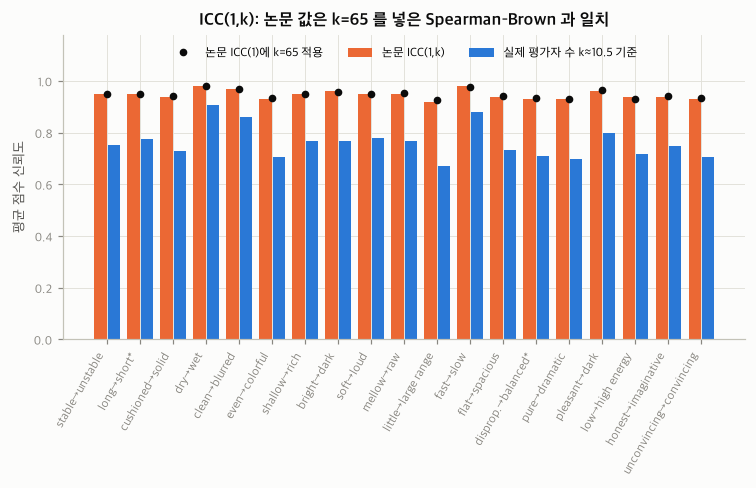

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(19)
ax.bar(x - 0.2, icc_tbl["paper ICC(1,k)"], width=0.38, color=viz.CAT[1], label="논문 ICC(1,k)")
ax.bar(x + 0.2, icc_tbl["ours ICC(1,k0)"], width=0.38, color=viz.CAT[0], label=f"실제 평가자 수 k≈{icc_tbl.k0.mean():.1f} 기준")
ax.plot(x, icc_tbl["SB(paper ICC1, k=65)"], "o", color=viz.INK, ms=4, label="논문 ICC(1)에 k=65 적용")
ax.set_xticks(x, S, rotation=60, ha="right")
ax.set_ylim(0, 1.18)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_ylabel("평균 점수 신뢰도")
ax.set_title("ICC(1,k): 논문 값은 k=65 를 넣은 Spearman–Brown 과 일치")
ax.legend(loc="upper center", ncol=3)
viz.save(fig, "pp_icc_k65")
plt.show()

- **[사실]** ICC(1)은 논문과 거의 같습니다(상관 0.98, 차이 대부분 0.03 이내).
- **[사실]** 논문의 ICC(1,k) 0.92–0.98은 논문 ICC(1)에 k=65를 넣은 Spearman–Brown 값과 0.01 이내로 일치합니다. 65는 CSV의 평가자 ID 수입니다.
  실제로 구간마다 평균에 들어간 평가자 수(k0≈10.5)로 계산하면 **0.67–0.91**입니다.
- **[가설]** 논문은 평가자 전체를 열로 둔 행렬에서 ICC(1,k)를 계산했을 가능성이 큽니다. 그렇다면 "평균 신뢰도 excellent"는 과대평가이고,
  실제 구간 평균의 신뢰도는 "moderate–good" 수준입니다. 이 값이 예측기 성능의 상한(노이즈 천장)을 정합니다(M1).

## 2. 커버리지
### 2.1 곡 × 길이 × 연주자

In [10]:
segs = pd.DataFrame([pp.parse_name(s) for s in sorted({m.name[:-4] for m in paths.PP_MIDI.glob("*.mid")})])
cov = segs.groupby(["piece", "n_bars"]).agg(
    files=("segment_id", "size"), units=("unit", "nunique"),
    performers=("performer", "nunique"),
    human=("is_score", lambda s: (~s).sum()), score=("is_score", "sum"))
print(cov.to_string())
print("총 파일", len(segs), "/ 악보 단위", segs.unit.nunique(), "/ 사람 연주자 ID", segs.loc[~segs.is_score, "performer"].nunique())
perf_piece = segs[~segs.is_score].groupby("performer").piece.agg(lambda s: ", ".join(sorted(set(viz.PIECE_SHORT[p] for p in s))))
print(perf_piece.sort_index(key=lambda s: s.astype(int)).to_string())

                           files  units  performers  human  score
piece              n_bars                                        
Beethoven_WoO80    8         238     17          14    204     34
Schubert_D935_no.3 4         117     13           9     91     26
Schubert_D960_mv2  8         221     17          13    204     17
                   16         67      9          13     58      9
Schubert_D960_mv3  8         481     37          13    444     37
                   16         78      6          13     72      6
총 파일 1202 / 악보 단위 99 / 사람 연주자 ID 20
performer
0                        D960 2악장, D960 3악장
1     D935 No.3, D960 2악장, D960 3악장, WoO 80
2     D935 No.3, D960 2악장, D960 3악장, WoO 80
3     D935 No.3, D960 2악장, D960 3악장, WoO 80
4                D960 2악장, D960 3악장, WoO 80
5                        D960 2악장, D960 3악장
6             D935 No.3, D960 2악장, D960 3악장
7                D960 2악장, D960 3악장, WoO 80
8                        D960 2악장, D960 3악장
9             D935 No.3, D960 

- **[사실]** WoO 80은 변주마다 8마디 구간 1개씩(17개)이고, 사람 12명 + Score + Score2가 연주했습니다. **변주 1·2는 없습니다.**
- **[사실]** 사람 연주자 ID는 20개입니다(논문은 25명). WoO 80 연주자 ID(11, 14, 18, 19, 22, 24, 26 등)는 다른 곡과 거의 겹치지 않습니다.
  - **[가설]** 연주자 ID를 곡마다 따로 붙였을 수 있습니다. 그렇다면 "같은 ID = 같은 사람"이라는 가정은 곡을 넘어서는 성립하지 않습니다.

In [11]:
WOO_SECTION = {1: "thema", 2: "var3", 3: "var4", 4: "var5", 5: "var6", 6: "var8", 7: "var9", 8: "var10", 9: "var12",
               10: "var15", 11: "var17", 12: "var18", 13: "var23", 14: "var25", 15: "var27", 16: "var28", 17: "var30"}
woo = segs[segs.piece == "Beethoven_WoO80"]
assert (woo.apply(lambda r: WOO_SECTION[r.segment] == r.section, axis=1)).all()
print(woo.groupby("section").performer.apply(lambda s: " ".join(sorted(s, key=lambda x: (not x.isdigit(), x.zfill(3))))).to_string())

section
thema    1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var10    1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var12    1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var15    1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var17    1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var18    1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var23    1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var25    1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var27    1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var28    1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var3     1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var30    1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var4     1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var5     1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var6     1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var8     1 2 3 4 7 11 14 18 19 22 24 26 Score Score2
var9     1 2 3 4 7 11 14 18 19 22 24 26 Score Score2


### 2.2 구간당 주석 수

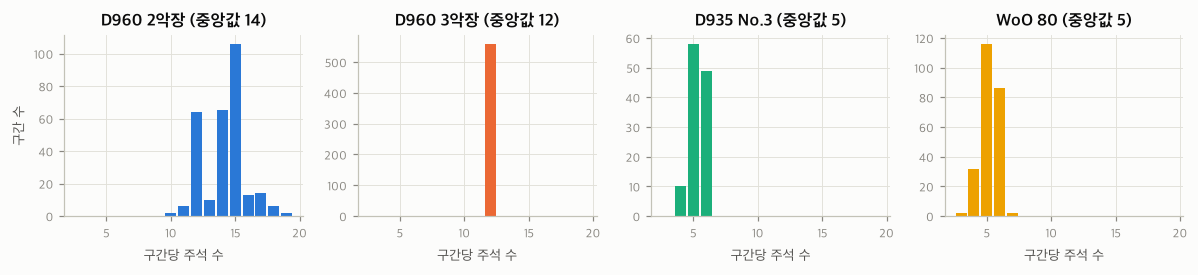

                    count  mean  std   min   25%   50%   75%   max
piece                                                             
Beethoven_WoO80     238.0   5.2  0.7   3.0   5.0   5.0   6.0   7.0
Schubert_D935_no.3  117.0   5.3  0.6   4.0   5.0   5.0   6.0   6.0
Schubert_D960_mv2   288.0  14.2  1.6  10.0  12.8  14.0  15.0  19.0
Schubert_D960_mv3   559.0  12.0  0.0  12.0  12.0  12.0  12.0  12.0


In [12]:
n_per_seg = keep.groupby(["piece", "segment_id"]).size().rename("n").reset_index()
fig, axes = plt.subplots(1, 4, figsize=(11, 2.6), sharey=False)
for ax, p in zip(axes, PIECES):
    v = n_per_seg.loc[n_per_seg.piece == p, "n"]
    ax.hist(v, bins=np.arange(2.5, 20.5, 1), color=viz.PIECE_COLORS[p], rwidth=0.85)
    ax.set_title(f"{viz.PIECE_SHORT[p]} (중앙값 {v.median():.0f})")
    ax.set_xlabel("구간당 주석 수")
axes[0].set_ylabel("구간 수")
fig.tight_layout()
viz.save(fig, "pp_annotations_per_segment")
plt.show()
print(n_per_seg.groupby("piece").n.describe().round(1).to_string())

### 2.3 평가자 집단 × 곡 — 완전 교란

In [13]:
xt_n = keep.groupby(["block", "piece"]).size().unstack(fill_value=0)[PIECES]
xt_u = keep.groupby(["block", "piece"]).user.nunique().unstack(fill_value=0)[PIECES]
print("주석 수\n", xt_n.to_string(), "\n\n평가자 수\n", xt_u.to_string())
print("\n평가자별 평가한 곡 조합:")
print(keep.groupby("user").piece.agg(lambda s: " + ".join(viz.PIECE_SHORT[p] for p in sorted(s.unique()))).value_counts().to_string())

주석 수
 piece        Schubert_D960_mv2  Schubert_D960_mv3  Schubert_D935_no.3  Beethoven_WoO80
block                                                                                 
B1(0-28)                  1300                  0                   0                0
B2(70-121)                2776               6708                   0                0
B3(201-211)                  0                  0                 624             1244 

평가자 수
 piece        Schubert_D960_mv2  Schubert_D960_mv3  Schubert_D935_no.3  Beethoven_WoO80
block                                                                                 
B1(0-28)                    10                  0                   0                0
B2(70-121)                  43                 33                   0                0
B3(201-211)                  0                  0                  11               11

평가자별 평가한 곡 조합:
piece
D960 2악장 + D960 3악장    32
D960 2악장               21
WoO 80 + D935 No.3     11
D960 3악장       

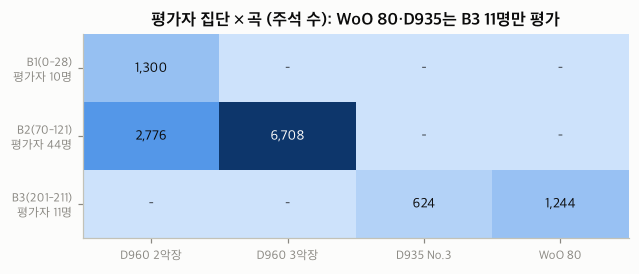

In [14]:
fig, ax = plt.subplots(figsize=(6.4, 2.4))
im = ax.imshow(xt_n.values, cmap=viz.seq_cmap(), aspect="auto")
ax.set_xticks(range(4), [viz.PIECE_SHORT[p] for p in PIECES])
n_block = keep.groupby("block").user.nunique()  # 곡별 최댓값이 아니라 집단 전체 인원 (B2는 곡마다 43·33명, 합쳐서 44명)
ax.set_yticks(range(3), [f"{b}\n평가자 {n_block[b]}명" for b in xt_n.index])
for i in range(3):
    for j in range(4):
        v = xt_n.values[i, j]
        ax.text(j, i, f"{v:,}" if v else "–", ha="center", va="center",
                color=viz.SURFACE if v > 3000 else viz.INK, fontsize=9)
ax.grid(False)
ax.set_title("평가자 집단 × 곡 (주석 수): WoO 80·D935는 B3 11명만 평가")
viz.save(fig, "pp_block_by_piece")
plt.show()

- **[사실]** WoO 80과 D935는 평가자 11명(ID 201–211)만 평가했고, 이들은 다른 곡을 평가하지 않았습니다. D960은 다른 54명이 평가했습니다.
- 그래서 **곡 간 라벨 차이는 평가자 집단 차이와 분리할 수 없습니다.**
  곡 홀드아웃 실험(예: D960으로 학습 → WoO 80으로 평가)에서 성능이 떨어지는 것도 곡이 바뀐 탓인지 평가자가 바뀐 탓인지 가릴 수 없습니다.
- **[사실]** WoO 80 구간의 주석 수 중앙값은 다른 곡보다 작습니다(2.2). WoO 80 라벨은 상대적으로 잡음이 큽니다.

### 2.4 같은 평가자의 반복 평가

In [15]:
g = keep.groupby(["user", "segment_id"]).size()
rep_idx = g[g > 1].index
rp = keep.set_index(["user", "segment_id"]).loc[rep_idx].reset_index().sort_values(["user", "segment_id", "row"])
print("반복된 (평가자, 구간) 쌍:", len(rep_idx), "/ 추가 행:", int((g[g > 1] - 1).sum()), "/ 최대 반복:", g.max())
print(rp.groupby(["block", "piece"]).size().unstack(fill_value=0).to_string())
first = rp.drop_duplicates(["user", "segment_id"], keep="first").set_index(["user", "segment_id"])[L]
second = rp[rp.duplicated(["user", "segment_id"], keep="first")].drop_duplicates(["user", "segment_id"]).set_index(["user", "segment_id"])[L]
first = first.loc[second.index]
retest = pd.DataFrame({
    "r(1차, 2차)": [first[c].corr(second[c]) for c in L],
    "완전 일치율": [np.mean((first[c] == second[c])[first[c].notna() & second[c].notna()]) for c in L],
    "평균 |차이|": [(first[c] - second[c]).abs().mean() for c in L],
}, index=S)
print(retest.round(2).to_string())
gap = rp.groupby(["user", "segment_id"]).row.agg(lambda s: s.max() - s.min())
print("CSV 안에서 두 평가 사이 행 간격: 중앙값", int(gap.median()))

반복된 (평가자, 구간) 쌍: 1309 / 추가 행: 1436 / 최대 반복: 4
piece       Schubert_D960_mv2  Schubert_D960_mv3
block                                           
B1(0-28)                   48                  0
B2(70-121)                826               1871
                         r(1차, 2차)  완전 일치율  평균 |차이|
stable→unstable               0.52    0.43     1.03
long→short*                   0.58    0.47     0.88
cushioned→solid               0.49    0.40     1.03
dry→wet                       0.69    0.44     0.94
clean→blurred                 0.62    0.40     1.05
even→colorful                 0.47    0.39     1.05
shallow→rich                  0.53    0.39     1.03
bright→dark                   0.62    0.52     0.68
soft→loud                     0.46    0.40     0.97
mellow→raw                    0.50    0.36     0.97
little→large range            0.51    0.37     0.98
fast→slow                     0.63    0.51     0.62
flat→spacious                 0.44    0.43     0.95
disprop.→balanced*            

- **[사실]** 반복 평가는 D960 구간에서만 나타나고, 주로 B2 평가자 몇 명(71, 121, 97, 70)에게 몰려 있습니다.
- **[사실]** 같은 평가자가 같은 구간을 다시 평가했을 때의 상관(재검사 r)은 0.40–0.69, 완전 일치율은 약 42%, 평균 차이는 약 0.9점입니다.
  평가자 한 명의 판단 자체가 흔들린다는 뜻이고, 이것이 단일 평가 신뢰도(ICC(1) 0.16–0.48)가 낮은 이유 중 하나입니다.
- **[가설]** 두 평가는 CSV에서 멀리 떨어져 있습니다(중앙값 약 1,900행). "2rounds"라는 이름처럼 두 수집 라운드에서 같은 구간을 다시 받은 것일 수 있습니다.

## 3. 분포
### 3.1 차원별 원점수 분포

findfont: Failed to find font weight bold for AppleGothic, now using 400.


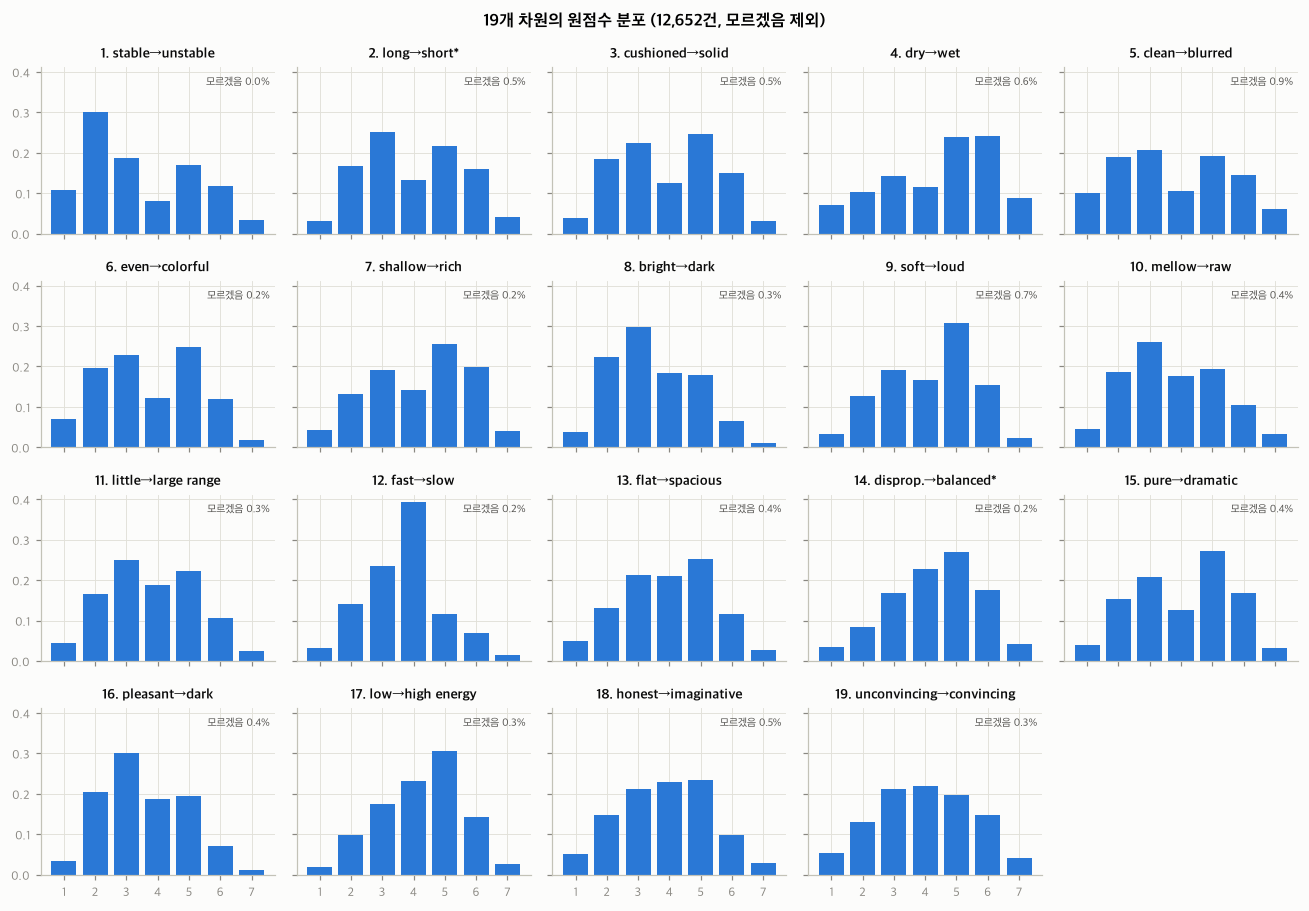

In [16]:
fig, axes = plt.subplots(4, 5, figsize=(12, 8.4), sharex=True, sharey=True)
for i, ax in enumerate(axes.flat):
    if i >= 19:
        ax.axis("off")
        continue
    v = keep[L[i]].dropna()
    share = v.round().value_counts(normalize=True).reindex(range(1, 8), fill_value=0)
    ax.bar(share.index, share.values, color=viz.CAT[0], width=0.8)
    idk_rate = keep[L[i]].isna().mean()
    ax.set_title(f"{i + 1}. {S[i]}", fontsize=9)
    ax.text(0.98, 0.95, f"모르겠음 {idk_rate:.1%}", transform=ax.transAxes, ha="right", va="top", fontsize=7, color=viz.INK2)
for ax in axes[-1]:
    ax.set_xticks(range(1, 8))
fig.suptitle("19개 차원의 원점수 분포 (12,652건, 모르겠음 제외)", fontsize=11, fontweight="bold")
fig.tight_layout()
viz.save(fig, "pp_rating_distributions")
plt.show()

### 3.2 곡별 구간 평균 — 논문 Table 2 재현

In [17]:
T2 = np.array([
    [2.96, 1.82, 3.35, 1.67, 3.94, 1.71, 3.31, 1.62], [3.33, 1.56, 4.48, 1.38, 3.90, 1.49, 3.63, 1.56],
    [3.74, 1.72, 4.13, 1.46, 3.68, 1.49, 3.92, 1.54], [2.88, 1.59, 3.99, 1.71, np.nan, 1.50, 3.87, 1.46],
    [4.26, 1.84, 3.59, 1.65, 3.42, 1.52, 3.09, 1.37], [3.66, 1.69, 3.58, 1.44, 3.84, 1.54, 3.59, 1.49],
    [3.41, 1.65, 4.10, 1.44, 4.03, 1.62, 3.91, 1.57], [3.82, 1.50, 3.13, 1.21, 3.13, 1.31, 3.99, 1.24],
    [3.75, 1.61, 4.48, 1.21, 3.50, 1.48, 3.73, 1.52], [3.48, 1.60, 4.02, 1.36, 3.58, 1.65, 3.54, 1.59],
    [4.13, 1.56, 4.35, 1.33, 3.83, 1.48, 3.63, 1.43], [4.23, 1.34, 3.24, 0.99, 3.40, 1.17, 3.62, 1.30],
    [4.20, 1.65, 3.68, 1.30, 3.90, 1.50, 3.87, 1.48], [3.36, 1.55, 3.92, 1.30, 3.98, 1.53, 4.16, 1.49],
    [3.98, 1.74, 3.90, 1.41, 4.32, 1.52, 4.05, 1.58], [3.99, 1.48, 3.06, 1.21, 3.13, 1.26, 4.10, 1.18],
    [3.96, 1.54, 3.66, 1.25, 4.25, 1.21, 4.02, 1.30], [3.81, 1.62, 4.44, 1.20, 3.84, 1.64, 3.69, 1.59],
    [3.69, 1.63, 4.22, 1.37, 3.64, 1.64, 3.77, 1.61]])
paper_m = pd.DataFrame(T2[:, ::2], index=S, columns=PIECES)
ours_m = pd.DataFrame([[keep.loc[keep.piece == p, c].mean() for p in PIECES] for c in L], index=S, columns=PIECES)
ours_s = pd.DataFrame([[keep.loc[keep.piece == p, c].std() for p in PIECES] for c in L], index=S, columns=PIECES)
delta = ours_m - paper_m
delta_rev = (8 - ours_m) - paper_m
print("평균 차이 (우리 − 논문)\n", delta.round(2).to_string())
print("\n곡별 최대 |차이|:", delta.abs().max().round(3).to_dict())
print("SD 최대 |차이|:", (ours_s - pd.DataFrame(T2[:, 1::2], index=S, columns=PIECES)).abs().max().round(3).to_dict())
print("D935 dry→wet 평균 (논문 '22(1.50)'):", round(ours_m.loc["dry→wet", "Schubert_D935_no.3"], 2))

평균 차이 (우리 − 논문)
                          Schubert_D960_mv2  Schubert_D960_mv3  Schubert_D935_no.3  Beethoven_WoO80
stable→unstable                       0.47              -0.02               -0.01             0.00
long→short*                           1.38              -0.87               -0.02             0.00
cushioned→solid                      -0.07              -0.02                0.02             0.00
dry→wet                               2.33               0.08                 NaN            -0.00
clean→blurred                         0.15              -0.04               -0.01             0.00
even→colorful                         0.15               0.08               -0.03            -0.01
shallow→rich                          1.26              -0.12               -0.03            -0.01
bright→dark                           0.04               0.05                0.02             0.00
soft→loud                             0.08              -0.02                0.12           

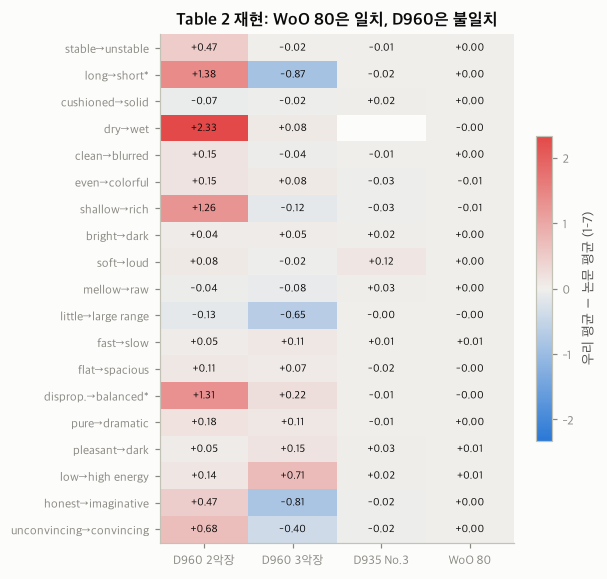

In [18]:
fig, ax = plt.subplots(figsize=(5.2, 6))
lim = np.nanmax(np.abs(delta.values))
im = ax.imshow(delta.values, cmap=viz.diverging_cmap(), vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(4), [viz.PIECE_SHORT[p] for p in PIECES])
ax.set_yticks(range(19), S)
for i in range(19):
    for j in range(4):
        v = delta.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=7, color=viz.INK)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.6, label="우리 평균 − 논문 평균 (1–7)")
ax.set_title("Table 2 재현: WoO 80은 일치, D960은 불일치")
viz.save(fig, "pp_table2_reproduction")
plt.show()

- **[사실]** WoO 80 열은 19개 차원 모두 0.015 이내로 재현됩니다. D935도 대부분 0.03 이내입니다(soft→loud만 0.12 차이).
  논문의 "22(1.50)"은 4.20으로 재현되어 오타로 보입니다.
- **[사실]** D960 2·3악장은 어떤 정제 방식(중복 포함·제거, 원 절차)으로도 재현되지 않습니다. 차이는 최대 약 2.3점입니다.
  일부 차원(2, 4, 7, 14, 19 등)은 우리 값을 8에서 뺀 값에 가깝지만 정확히 일치하지는 않습니다.
- **[가설]** 논문의 D960 통계가 공개 CSV와 다른 버전의 데이터(예: 문항 방향을 바꾸기 전 또는 후)에서 계산되었을 수 있습니다.
  다만 D960 안에서 두 평가자 집단(B1, B2)의 평균은 서로 비슷하므로, 공개 CSV 자체는 D960 안에서 일관됩니다.
  **확정하려면 저자에게 문의가 필요합니다.**

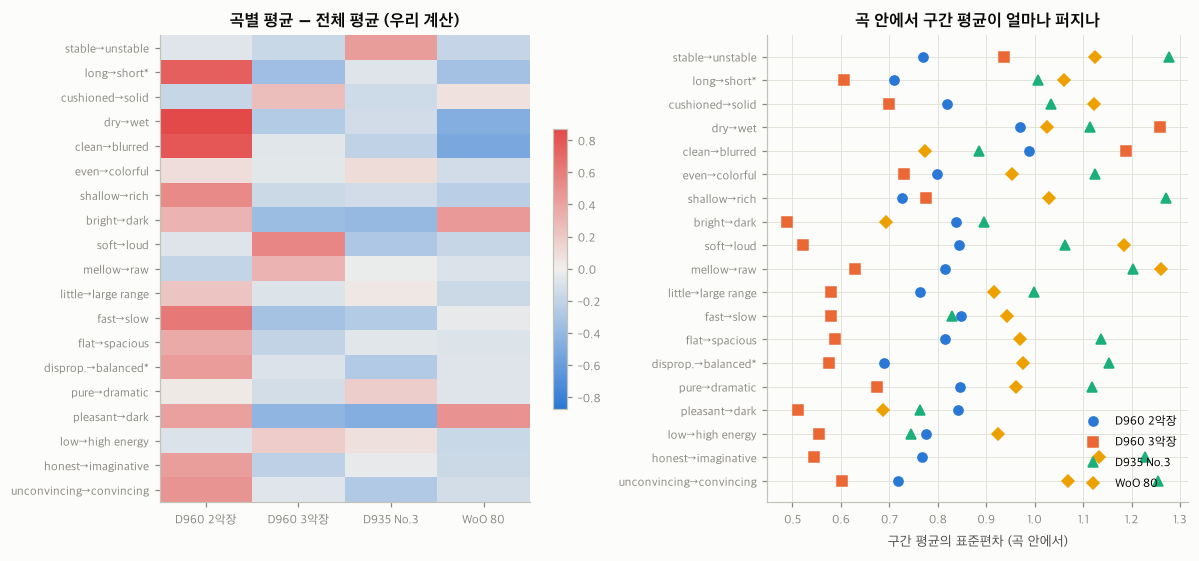

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
centered = ours_m.sub(ours_m.mean(axis=1), axis=0)
lim = np.abs(centered.values).max()
im = axes[0].imshow(centered.values, cmap=viz.diverging_cmap(), vmin=-lim, vmax=lim, aspect="auto")
axes[0].set_xticks(range(4), [viz.PIECE_SHORT[p] for p in PIECES])
axes[0].set_yticks(range(19), S)
axes[0].grid(False)
axes[0].set_title("곡별 평균 − 전체 평균 (우리 계산)")
fig.colorbar(im, ax=axes[0], shrink=0.6)
seg_k = pp.segment_means(keep)
for p in PIECES:
    v = seg_k[seg_k.piece == p]
    axes[1].plot(v[L].std().values, range(19), viz.PIECE_MARKERS[p], color=viz.PIECE_COLORS[p], label=viz.PIECE_SHORT[p], ms=6)
axes[1].set_yticks(range(19), S)
axes[1].invert_yaxis()
axes[1].set_xlabel("구간 평균의 표준편차 (곡 안에서)")
axes[1].set_title("곡 안에서 구간 평균이 얼마나 퍼지나")
axes[1].legend(loc="lower right")
fig.tight_layout()
viz.save(fig, "pp_piece_means")
plt.show()

- 곡마다 평균 프로파일이 뚜렷하게 다릅니다. 예를 들어 D960 3악장은 "느림" 쪽이 낮고(빠르게 들림) "어두움"이 낮습니다.
  하지만 2.3에서 보았듯이 이 차이에는 평가자 집단의 차이가 섞여 있습니다.

In [20]:
rat.to_parquet(paths.INTERIM / "pp_ratings_clean.parquet")
keep.to_parquet(paths.INTERIM / "pp_ratings_keep.parquet")
seg_clean.to_parquet(paths.INTERIM / "pp_segments_clean.parquet")
pub_df.rename_axis("segment_id").reset_index().to_parquet(paths.INTERIM / "pp_segments_published_root.parquet")
print("saved:", sorted(p.name for p in paths.INTERIM.glob("pp_*.parquet")))

saved: ['pp_features.parquet', 'pp_note_params.parquet', 'pp_ratings_clean.parquet', 'pp_ratings_keep.parquet', 'pp_segments_clean.parquet', 'pp_segments_published_root.parquet', 'pp_variance_components.parquet']


## 4. 신뢰도와 분산 분해 (M1)

평가자 집단과 곡이 완전히 겹치므로(2.3) **두 집단을 따로** 분석합니다.
- D960 집단: 평가자 54명, 구간당 약 11명
- WoO80+D935 집단: 평가자 11명, 구간당 약 5명

구간 점수의 참 분산을 둘로 나눕니다.
- **단위 간 분산**: 같은 악보 구간(단위)인지에 따라 달라지는 몫. 곡·조성·악상 같은 악보 내용입니다.
- **단위 내 분산**: 같은 악보 구간 안에서 연주자에 따라 달라지는 몫. "같은 곡의 연주끼리 비교"할 때 쓸 수 있는 신호는 이쪽뿐입니다.

추정은 세 가지로 서로 검증합니다: 모멘트 추정(평가자 관대도 보정 전·후), 교차 무선효과 MixedLM(REML), 모형 없는 분할-반.
계산은 `scripts/variance_components.py` → `data/interim/pp_variance_components.parquet` 에 캐시되어 있습니다.

In [21]:
vc = pd.read_parquet(paths.INTERIM / "pp_variance_components.parquet")
vm = vc[vc.variant == "mean"].copy()
vm["mlm_share"] = vm.mlm_unit / (vm.mlm_unit + vm.mlm_within)
print("MixedLM 수렴:", vm.mlm_converged.all())
print("단위 몫: 모멘트 vs MixedLM 상관", round(vm[["share_unit_adj", "mlm_share"]].corr().iloc[0, 1], 3))
print("단위 내 신뢰도: 모멘트 vs 분할-반 상관", round(vm[["rel_within_mean_raw", "sh_within"]].corr().iloc[0, 1], 3))
show = vm.pivot_table(index="dim", columns="group", values=["share_unit_adj", "rel_mean_raw", "rel_within_mean_raw"], sort=False)
print(show.round(2).to_string())

MixedLM 수렴: True
단위 몫: 모멘트 vs MixedLM 상관 0.989
단위 내 신뢰도: 모멘트 vs 분할-반 상관 0.998
                        share_unit_adj            rel_mean_raw            rel_within_mean_raw           
group                             D960 WoO80+D935         D960 WoO80+D935                D960 WoO80+D935
dim                                                                                                     
stable→unstable                   0.21       0.18         0.72       0.78                0.67       0.74
long→short*                       0.57       0.59         0.75       0.72                0.55       0.51
cushioned→solid                   0.32       0.45         0.69       0.78                0.61       0.66
dry→wet                           0.27       0.33         0.91       0.77                0.88       0.69
clean→blurred                     0.25       0.48         0.87       0.52                0.84       0.32
even→colorful                     0.49       0.20         0.68       0.71         

findfont: Failed to find font weight bold for AppleGothic, now using 400.


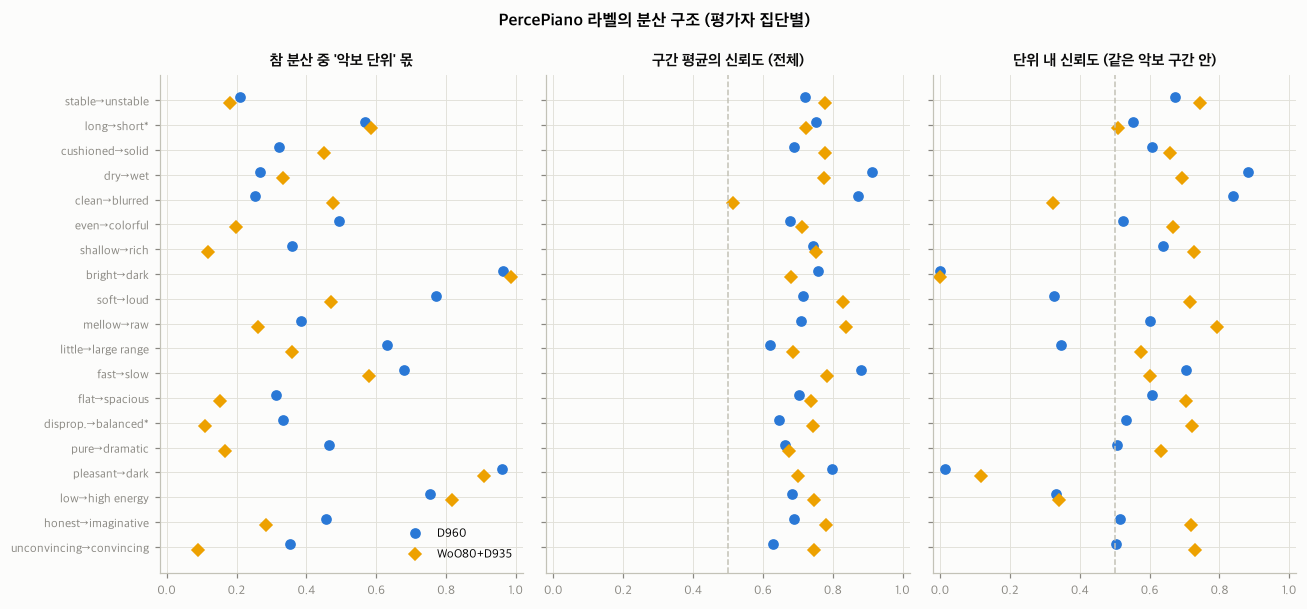

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5.6), sharey=True)
order_dims = S
for ax, (col, title) in zip(axes, [("share_unit_adj", "참 분산 중 '악보 단위' 몫"),
                                   ("rel_mean_raw", "구간 평균의 신뢰도 (전체)"),
                                   ("rel_within_mean_raw", "단위 내 신뢰도 (같은 악보 구간 안)")]):
    for j, (g, mk, colr) in enumerate([("D960", "o", viz.CAT[0]), ("WoO80+D935", "D", viz.CAT[3])]):
        v = vm[vm.group == g].set_index("dim").loc[order_dims, col]
        ax.plot(v.values, np.arange(19) + (j - 0.5) * 0.25, mk, color=colr, ms=6, label=g)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(-0.02, 1.02)
axes[0].set_yticks(range(19), order_dims)
axes[0].invert_yaxis()
axes[0].legend(loc="lower right")
for ax in axes[1:]:
    ax.axvline(0.5, color=viz.AXIS, lw=1, ls="--")
fig.suptitle("PercePiano 라벨의 분산 구조 (평가자 집단별)", fontsize=11, fontweight="bold")
fig.tight_layout()
viz.save(fig, "pp_variance_structure")
plt.show()

- **[사실]** 세 추정법이 서로 맞습니다(단위 몫 모멘트–MixedLM 상관 0.99, 단위 내 신뢰도 모멘트–분할-반 상관도 높음).
- **[사실]** bright→dark, pleasant→dark는 참 분산의 90% 이상이 악보 단위에서 나옵니다. 단위 내 신뢰도는 0에 가깝습니다.
  조성·악상이 정하는 차원이라, 같은 곡의 연주끼리는 거의 구분되지 않습니다. low→high energy와 soft→loud(D960)도 단위 몫이 큽니다.
- **[사실]** timing, pedal(dry→wet, clean→blurred), tempo(fast→slow)는 단위 내 신뢰도가 높은 편입니다. 연주마다 실제로 다르게 지각되는 차원입니다.

### 4.2 반례 점검: 단위 내 신호의 상당 부분은 '무표정 악보 연주 vs 사람' 차이였습니다

단위 내 분산에는 Score/Score2(악보 그대로의 무표정 렌더)와 사람 연주의 차이가 포함됩니다. 이것을 빼고 사람 연주만으로 다시 계산합니다.

In [23]:
rows = []
subsets = {"D960": rat[rat.block != "B3(201-211)"], "WoO80+D935": rat[rat.block == "B3(201-211)"],
           "WoO80": rat[rat.piece == "Beethoven_WoO80"]}
for g, d in subsets.items():
    for sub, dd in [("Score 포함", d), ("사람만", d[~d.is_score])]:
        for i, c in enumerate(L):
            a = su.variance_decomposition(dd, c, rater_adjust=False)
            rows.append({"group": g, "subset": sub, "dim": S[i], "rel_within": a["rel_within_mean"], "k": a["k_mean"]})
hw = pd.DataFrame(rows)
hw_t = hw.pivot_table(index="dim", columns=["group", "subset"], values="rel_within", sort=False)
print(hw_t.round(2).to_string())
print("\n단위 내 신뢰도 ≥ 0.5 인 차원 수:")
print((hw_t >= 0.5).sum().to_string())

group                       D960       WoO80+D935          WoO80      
subset                  Score 포함   사람만   Score 포함   사람만 Score 포함   사람만
dim                                                                   
stable→unstable             0.67  0.64       0.74  0.44     0.68  0.45
long→short*                 0.55  0.54       0.51  0.00     0.37  0.03
cushioned→solid             0.61  0.55       0.66  0.26     0.61  0.24
dry→wet                     0.88  0.88       0.69  0.29     0.60  0.25
clean→blurred               0.84  0.83       0.32  0.11     0.16  0.05
even→colorful               0.52  0.39       0.67  0.35     0.57  0.40
shallow→rich                0.64  0.58       0.73  0.33     0.61  0.29
bright→dark                 0.00  0.00       0.00  0.04     0.00  0.02
soft→loud                   0.32  0.18       0.72  0.26     0.71  0.25
mellow→raw                  0.60  0.45       0.79  0.36     0.80  0.34
little→large range          0.34  0.23       0.58  0.27     0.59  0.30
fast→s

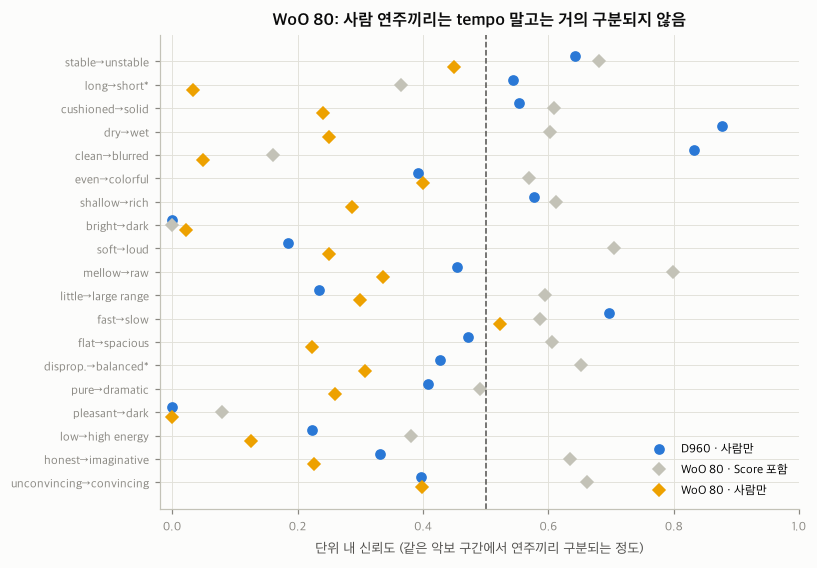

In [24]:
fig, ax = plt.subplots(figsize=(7.5, 5.6))
for j, (g, sub, mk, colr, lab) in enumerate([
        ("D960", "사람만", "o", viz.CAT[0], "D960 · 사람만"),
        ("WoO80", "Score 포함", "D", viz.AXIS, "WoO 80 · Score 포함"),
        ("WoO80", "사람만", "D", viz.CAT[3], "WoO 80 · 사람만")]):
    v = hw_t[(g, sub)].loc[S]
    ax.plot(v.values, np.arange(19) + (j - 1) * 0.22, mk, color=colr, ms=6, label=lab)
ax.axvline(0.5, color=viz.INK2, lw=1, ls="--")
ax.set_yticks(range(19), S)
ax.invert_yaxis()
ax.set_xlim(-0.02, 1.0)
ax.set_xlabel("단위 내 신뢰도 (같은 악보 구간에서 연주끼리 구분되는 정도)")
ax.set_title("WoO 80: 사람 연주끼리는 tempo 말고는 거의 구분되지 않음")
ax.legend(loc="lower right")
viz.save(fig, "pp_within_unit_human_only")
plt.show()

In [25]:
# 평가자 수가 적은 탓인지: WoO 80 사람만의 단일 평가 신뢰도를 k=11(D960 수준)로 외삽
woo_h = hw[(hw.group == "WoO80") & (hw.subset == "사람만")].set_index("dim")
k_now = woo_h.k.mean()
r1 = woo_h.rel_within / (k_now - (k_now - 1) * woo_h.rel_within)
proj = pd.DataFrame({"현재 (k≈%.1f)" % k_now: woo_h.rel_within, "k=11 외삽": su.spearman_brown(r1, 11), "k=20 외삽": su.spearman_brown(r1, 20)})
print(proj.round(2).to_string())

                         현재 (k≈5.2)  k=11 외삽  k=20 외삽
dim                                                  
stable→unstable                0.45     0.63     0.76
long→short*                    0.03     0.07     0.11
cushioned→solid                0.24     0.40     0.55
dry→wet                        0.25     0.41     0.56
clean→blurred                  0.05     0.10     0.17
even→colorful                  0.40     0.58     0.72
shallow→rich                   0.29     0.46     0.61
bright→dark                    0.02     0.04     0.08
soft→loud                      0.25     0.41     0.56
mellow→raw                     0.34     0.52     0.66
little→large range             0.30     0.47     0.62
fast→slow                      0.52     0.70     0.81
flat→spacious                  0.22     0.38     0.52
disprop.→balanced*             0.31     0.48     0.63
pure→dramatic                  0.26     0.42     0.57
pleasant→dark                  0.00     0.00     0.00
low→high energy             

- **[사실]** WoO 80에서 사람 연주끼리만 보면 단위 내 신뢰도가 0.5 이상인 차원은 fast→slow(0.52) 하나입니다.
  articulation(0.03), clean→blurred(0.05)처럼 거의 0인 차원도 있습니다. Score를 포함했을 때 높게 보였던 신뢰도는 주로 무표정 렌더와 사람의 차이였습니다.
- **[사실]** D960은 사람만으로도 7개 차원이 0.5 이상입니다(timing, articulation, cushioned, dry→wet 0.88, clean→blurred 0.83, rich, tempo).
- **[가설]** WoO 80은 구간당 평가자가 약 5명뿐입니다. 평가자를 11명으로 늘린다고 외삽하면 신뢰도가 올라가는 차원이 있습니다(위 표).
  그러니 "WoO 80 연주들이 서로 비슷하게 들린다"가 아니라 "평가가 적어서 구분이 안 된다"일 수도 있습니다.

> **체크포인트 2 결론**
> - PercePiano의 WoO 80 라벨은 "기계적(무표정)인가 사람다운가"는 강하게 구분합니다(6장 z ≈ −3).
>   하지만 **사람 수준 연주들 사이의 순위는 tempo 말고는 거의 구분하지 못합니다.**

### 4.3 노이즈 천장 — 예측기 R²의 상한

구간 평균(관측값)을 맞히는 예측기의 R² 상한은 구간 평균의 신뢰도 rel = σ²_참 / (σ²_참 + σ²_오차/k) 입니다(rel²가 아님).

In [26]:
ceil = vm.pivot_table(index="dim", columns="group", values=["rel_mean_raw", "rel_within_mean_raw"], sort=False)
ceil.columns = [f"{a}|{b}" for a, b in ceil.columns]
print(ceil.round(2).to_string())
print("\n19차원 평균 천장 (전체 기준):", vm.groupby("group").rel_mean_raw.mean().round(3).to_dict())
print("19차원 평균 천장 (단위 내 기준):", vm.groupby("group").rel_within_mean_raw.mean().round(3).to_dict())

                         rel_mean_raw|D960  rel_mean_raw|WoO80+D935  rel_within_mean_raw|D960  rel_within_mean_raw|WoO80+D935
dim                                                                                                                          
stable→unstable                       0.72                     0.78                      0.67                            0.74
long→short*                           0.75                     0.72                      0.55                            0.51
cushioned→solid                       0.69                     0.78                      0.61                            0.66
dry→wet                               0.91                     0.77                      0.88                            0.69
clean→blurred                         0.87                     0.52                      0.84                            0.32
even→colorful                         0.68                     0.71                      0.52                         

- **[사실]** 전체 기준 천장은 19차원 평균 약 0.72–0.74입니다. 보고된 예측 성능(R² 0.397, HAN 원 논문 / 0.533, MuQ, Dhiman 2026)은 이 천장의 약 55–75%입니다.
  두 값의 분할 방식(곡 기준, 연주자 기준, 무작위)이 서로 다르고 우리 천장 계산과도 다르므로, 비교는 대략적인 참고로만 씁니다.
- **[사실]** 단위 내 기준 천장은 훨씬 낮습니다. 같은 곡의 연주끼리 구분하는 과제의 상한은 차원에 따라 0에 가깝습니다.
  전체 R²가 높아도, 그 대부분이 "어떤 곡의 어느 구간인지" 맞힌 결과일 수 있습니다.

### 4.4 민감도: 반복 평가를 평균하지 않고 그대로 두면

In [27]:
vk = vc[vc.variant == "keep"].set_index(["group", "dim"])
vmm = vm.set_index(["group", "dim"])
print("단위 내 신뢰도 최대 |차이|:", round((vk.rel_within_mean_raw - vmm.rel_within_mean_raw).abs().max(), 3))
print("단위 몫 최대 |차이|:", round((vk.share_unit_adj - vmm.share_unit_adj).abs().max(), 3))

단위 내 신뢰도 최대 |차이|: 0.116
단위 몫 최대 |차이|: 0.031


- 반복 평가 처리 방식에 따른 차이는 결론을 바꿀 정도가 아닙니다(D960에서만 생기는 차이).

## 5. 차원 구조 — 19개 차원은 실제로 몇 개인가

In [28]:
seg = pd.read_parquet(paths.INTERIM / "pp_segments_clean.parquet")
seg["group"] = np.where(seg.piece.isin(["Beethoven_WoO80", "Schubert_D935_no.3"]), "WoO80+D935", "D960")
pca_rows = []
for g, d in seg.groupby("group"):
    for level, X in [("구간 평균", d[L]), ("단위 내 편차", d[L] - d.groupby("unit")[L].transform("mean"))]:
        Z = (X - X.mean()) / X.std()
        ev = np.linalg.eigvalsh(np.corrcoef(Z.T.to_numpy()))[::-1]
        r = ev / ev.sum()
        pca_rows.append({"group": g, "level": level, "PC1": r[0], "PC2": r[1], "PC3": r[2],
                         "80%에 필요한 PC 수": int(np.searchsorted(np.cumsum(r), 0.8) + 1),
                         "참여비(유효 차원)": ev.sum() ** 2 / (ev ** 2).sum()})
print(pd.DataFrame(pca_rows).round(2).to_string(index=False))

     group   level  PC1  PC2  PC3  80%에 필요한 PC 수  참여비(유효 차원)
      D960   구간 평균 0.46 0.21 0.09              4        3.65
      D960 단위 내 편차 0.45 0.15 0.11              5        4.10
WoO80+D935   구간 평균 0.55 0.12 0.09              4        3.02
WoO80+D935 단위 내 편차 0.55 0.10 0.08              5        3.03


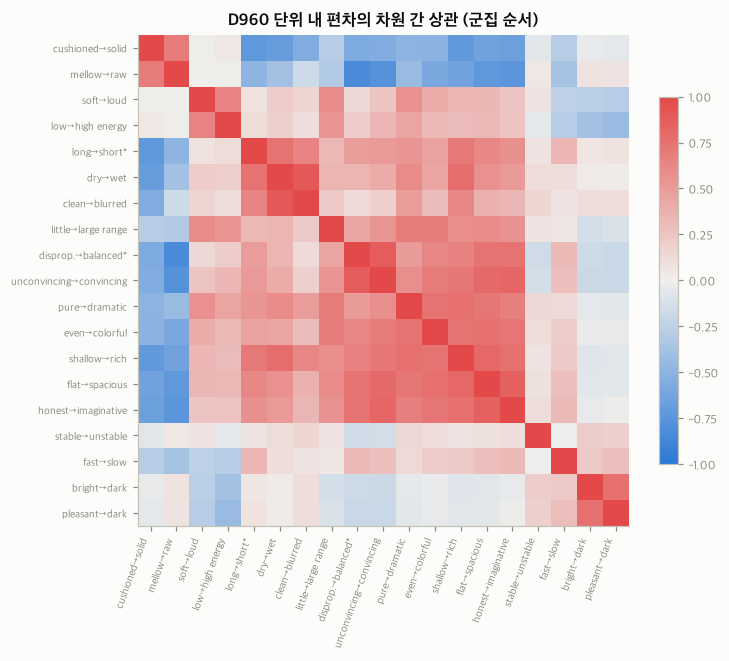

In [29]:
import scipy.cluster.hierarchy as sch
d960 = seg[seg.group == "D960"]
W = d960[L] - d960.groupby("unit")[L].transform("mean")
C = W.corr().to_numpy()
link = sch.linkage(1 - C[np.triu_indices(19, 1)], method="average")
ordr = sch.leaves_list(link)
fig, ax = plt.subplots(figsize=(7.2, 6.2))
im = ax.imshow(C[np.ix_(ordr, ordr)], cmap=viz.diverging_cmap(), vmin=-1, vmax=1)
ax.set_xticks(range(19), [S[i] for i in ordr], rotation=70, ha="right", fontsize=7)
ax.set_yticks(range(19), [S[i] for i in ordr], fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7)
ax.set_title("D960 단위 내 편차의 차원 간 상관 (군집 순서)")
viz.save(fig, "pp_dim_correlation_within")
plt.show()

- **[사실]** 1주성분이 분산의 45–55%를 설명하고, 참여비(유효 차원 수)는 약 3–4입니다. 19개 라벨은 독립적인 19개 신호가 아닙니다.
- 1주성분은 rich·spacious·imaginative·convincing·dramatic·balanced가 함께 움직이고 mellow→raw가 반대인 **"전반적 호감·표현성" 요인**입니다.
  **[가설]** 평가자가 전체 인상을 여러 문항에 퍼뜨리는 후광 효과일 수 있습니다. 반대로 실제 연주 특성이 함께 움직이는 것일 수도 있습니다.
  M2에서 MIDI 특징과 대조해 구분합니다.

## 6. 무표정 악보 연주(Score/Score2)와 사람 연주

In [30]:
zrows = []
for g, d in seg.groupby("group"):
    hum = d[~d.is_score]
    mu = hum.groupby("unit")[L].mean()
    pooled_sd = (hum[L] - hum.groupby("unit")[L].transform("mean")).std()
    for sc in ["Score", "Score2"]:
        s = d[d.performer == sc]
        if s.empty:
            continue
        z = (s.set_index("unit")[L] - mu.loc[s.unit].to_numpy()) / pooled_sd.to_numpy()
        zrows.append(pd.Series(z.mean().to_numpy(), index=S, name=f"{g} · {sc} (n={len(s)})"))
zt = pd.concat(zrows, axis=1)
print(zt.round(2).to_string())

                         D960 · Score (n=69)  WoO80+D935 · Score (n=30)  WoO80+D935 · Score2 (n=30)
stable→unstable                        -0.73                      -2.79                       -2.89
long→short*                            -0.57                      -2.49                       -2.85
cushioned→solid                         1.48                       2.92                        2.79
dry→wet                                -0.78                      -3.10                       -3.20
clean→blurred                          -0.41                      -1.41                       -1.69
even→colorful                          -2.01                      -2.60                       -2.68
shallow→rich                           -1.67                      -3.27                       -3.20
bright→dark                             0.42                      -0.16                       -0.36
soft→loud                              -0.97                       3.14                        3.30


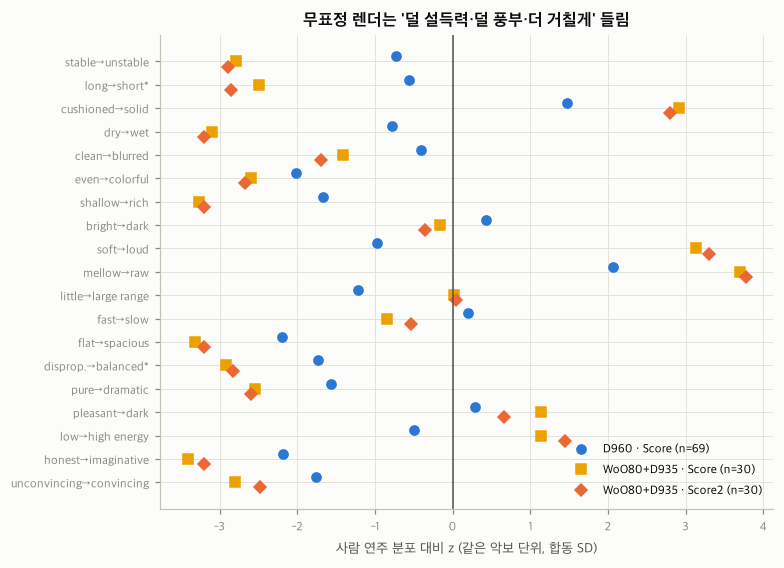

In [31]:
fig, ax = plt.subplots(figsize=(7.2, 5.6))
markers = ["o", "s", "D"]
colors = [viz.CAT[0], viz.CAT[3], viz.CAT[1]]
for j, col in enumerate(zt.columns):
    ax.plot(zt[col].values, np.arange(19) + (j - 1) * 0.22, markers[j], color=colors[j], ms=6, label=col)
ax.axvline(0, color=viz.INK2, lw=1)
ax.set_yticks(range(19), S)
ax.invert_yaxis()
ax.set_xlabel("사람 연주 분포 대비 z (같은 악보 단위, 합동 SD)")
ax.set_title("무표정 렌더는 '덜 설득력·덜 풍부·더 거칠게' 들림")
ax.legend(loc="lower right")
viz.save(fig, "pp_score_vs_human")
plt.show()

- **[사실]** 무표정 렌더는 사람 연주보다 convincing·rich·spacious·imaginative·dramatic이 크게 낮고, mellow→raw·cushioned→solid가 높게 평가됩니다(WoO80+D935 집단에서 |z|≈3).
  라벨이 "표현이 있는 연주 vs 기계적 연주"를 강하게 반영한다는 근거입니다.
- **[사실]** soft→loud는 집단에 따라 방향이 반대입니다. WoO80+D935에서는 무표정 렌더가 더 크게(z≈+3.1–3.3), D960에서는 더 작게(z≈−1.0) 평가됩니다.
  1.4에서 본 이 문항의 부호 차이와 연결됩니다. M2에서 실제 벨로시티로 확인합니다.

## 7. 연주자 일관성 — 라벨이 연주자 정체성을 담는가

In [32]:
rng = np.random.default_rng(0)
perf_rows = []
for g, d in seg[~seg.is_score].groupby("group"):
    Wd = d[L] - d.groupby("unit")[L].transform("mean")
    Wd["performer"], Wd["piece"] = d.performer.to_numpy(), d.piece.to_numpy()
    for i, c in enumerate(L):
        def eta(perf):
            m = Wd.groupby([Wd.piece, perf])[c].transform("mean")
            return 1 - ((Wd[c] - m) ** 2).sum() / ((Wd[c] - Wd[c].mean()) ** 2).sum()
        obs = eta(Wd.performer)
        null = np.array([eta(Wd.groupby("piece").performer.transform(lambda s: rng.permutation(s.to_numpy()))) for _ in range(200)])
        perf_rows.append({"group": g, "dim": S[i], "eta2": obs, "null 평균": null.mean(), "p(순열)": (null >= obs).mean()})
pt_ = pd.DataFrame(perf_rows)
print(pt_.pivot_table(index="dim", columns="group", values=["eta2", "null 평균"], sort=False).round(2).to_string())

                         eta2            null 평균           
group                    D960 WoO80+D935    D960 WoO80+D935
dim                                                        
stable→unstable          0.31       0.22    0.03       0.06
long→short*              0.43       0.10    0.03       0.06
cushioned→solid          0.38       0.07    0.03       0.06
dry→wet                  0.50       0.09    0.03       0.06
clean→blurred            0.49       0.16    0.03       0.06
even→colorful            0.16       0.15    0.03       0.06
shallow→rich             0.35       0.14    0.03       0.06
bright→dark              0.16       0.07    0.03       0.06
soft→loud                0.08       0.11    0.03       0.06
mellow→raw               0.23       0.19    0.03       0.06
little→large range       0.09       0.20    0.03       0.06
fast→slow                0.53       0.31    0.03       0.06
flat→spacious            0.23       0.15    0.03       0.06
disprop.→balanced*       0.20       0.14

- **[사실]** D960에서 연주자는 단위 내 편차의 9–53%를 설명합니다(우연 수준 약 3%). fast→slow 0.53, dry→wet 0.50, clean→blurred 0.49입니다.
  같은 연주자는 구간이 바뀌어도 비슷하게 지각됩니다. 그래서 **연주자 기준 분할을 하지 않으면 연주자 스타일 암기로 성능이 부풀 수 있습니다.**
- 주의: D960은 같은 연주에서 나온 8마디·16마디 구간이 겹치므로, η²의 일부는 같은 녹음을 두 번 센 효과입니다.

## 8. MIDI·정렬 특징과 라벨 (M2)

- 정렬: 각 연주 MIDI → 자기 악보 구간 `score_xml/{stem}_Score_{seg}.musicxml`, parangonar `AutomaticNoteMatcher` (`scripts/align_percepiano.py`)
- 원 논문은 Nakamura HMM 정렬 도구를 썼습니다. 파이프라인이 다르므로 특징 값이 원 논문의 VirtuosoNet 특징과 다를 수 있습니다.

In [33]:
feat = pd.read_parquet(paths.INTERIM / "pp_features.parquet")
feat["mr_score"] = feat.match / feat.score_notes
feat["mr_perf"] = feat.match / feat.perf_notes_pt
print("정렬 오류:", int(feat.get("align_error", pd.Series(dtype=object)).notna().sum()), "/", len(feat))
print(feat.groupby(["piece", "n_bars", "is_score"])[["mr_score", "mr_perf"]].median().round(3).to_string())
print("악보 쪽 매치율 < 0.8 인 구간:", int((feat.mr_score < 0.8).sum()))
print(feat.loc[feat.mr_score < 0.8, ["segment_id", "score_notes", "perf_notes_pt", "match"]].to_string(index=False))

정렬 오류: 0 / 1202
                                    mr_score  mr_perf
piece              n_bars is_score                   
Beethoven_WoO80    8      False        0.989    0.985
                          True         1.000    1.000
Schubert_D935_no.3 4      False        0.971    0.986
                          True         1.000    1.000
Schubert_D960_mv2  8      False        0.988    0.988
                          True         1.000    1.000
                   16     False        0.983    0.985
                          True         1.000    1.000
Schubert_D960_mv3  8      False        1.000    0.784
                          True         1.000    0.778
                   16     False        0.993    0.746
                          True         1.000    0.758
악보 쪽 매치율 < 0.8 인 구간: 17
                       segment_id  score_notes  perf_notes_pt  match
Beethoven_WoO80_var25_8bars_19_14          131            143     81
   Schubert_D935_no.3_4bars_12_13          130             95     

- **[사실]** 1,202개 구간이 모두 정렬됩니다. 악보 쪽 매치율 중앙값은 0.97–1.00입니다.
- **[사실]** D960 3악장은 연주 쪽 매치율이 약 0.78로 낮습니다. 무표정 Score MIDI도 마찬가지입니다.
  원인은 악보의 두 음 트레몰로(`<tremolo>`)입니다. MIDI는 반복음으로 풀어서 연주하지만, partitura는 악보에 적힌 두 음만 읽습니다.
  악보 쪽 음은 거의 다 정렬되므로 특징은 정렬된 음만으로 계산합니다.
- 악보 쪽 매치율이 0.8 미만인 17개 구간(대부분 D935 단위 9·13)은 특징 분석에서 뺍니다.

In [34]:
F = ["log_tempo", "tempo_logstd", "tempo_volatility", "timing_std_ms", "articulation_median", "articulation_iqr",
     "vel_mean", "vel_std", "vel_range", "pedal_down_ratio", "pedal_presses_per_s", "notes_per_s"]
fl = seg.merge(feat.drop(columns=["piece", "unit", "performer", "is_score", "n_bars"]), on="segment_id")
fl = fl[fl.mr_score >= 0.8].copy()
fl["log_tempo"] = np.log2(fl.tempo_median_bpm)
fl["cluster"] = fl.piece + "|" + fl.performer
print("분석 구간:", len(fl))
print(fl.groupby("is_score")[["vel_mean", "vel_std", "vel_n_unique", "pedal_down_ratio", "timing_std_ms", "tempo_logstd"]].median().round(2).to_string())

분석 구간: 1185
          vel_mean  vel_std  vel_n_unique  pedal_down_ratio  timing_std_ms  tempo_logstd
is_score                                                                                
False        58.11    13.35          44.0              0.46          18.99          0.24
True         66.39     7.37           3.0              0.00           0.00          0.00


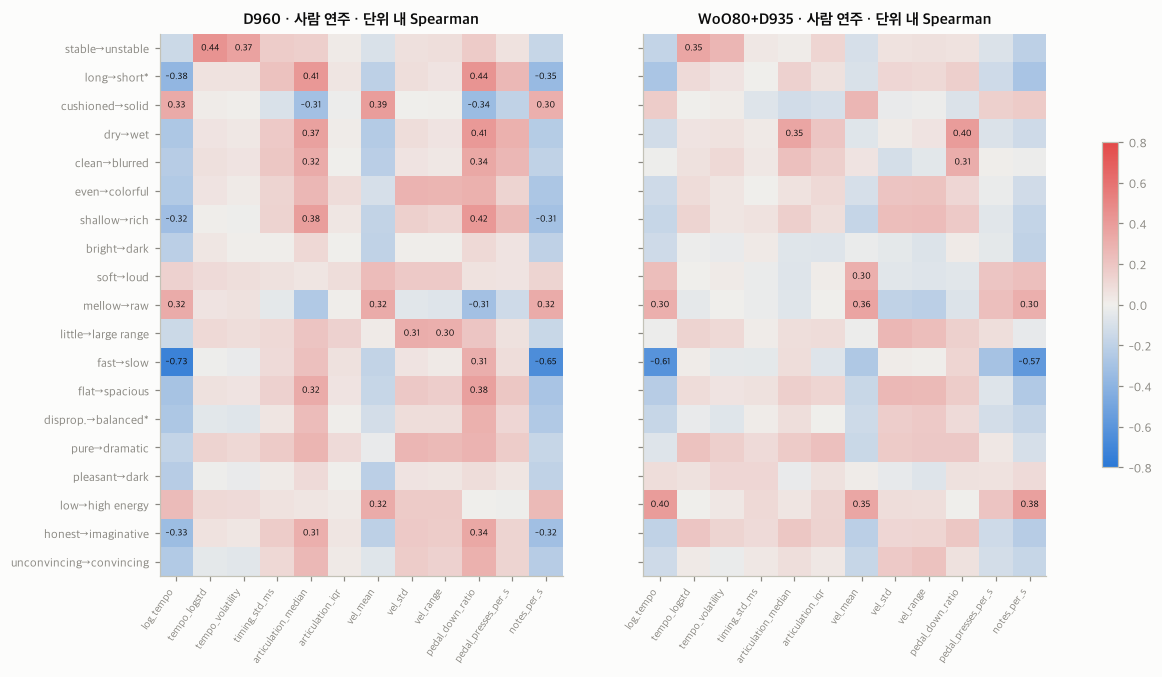

In [35]:
def within(df, cols):
    return df[cols] - df.groupby("unit")[cols].transform("mean")

heat = {}
for g, dg in fl[~fl.is_score].groupby("group"):
    W = within(dg, L + F)
    heat[g] = pd.DataFrame([[W[f].corr(W[l], method="spearman") for f in F] for l in L], index=S, columns=F)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.4), sharey=True)
for ax, (g, h) in zip(axes, heat.items()):
    im = ax.imshow(h.values, cmap=viz.diverging_cmap(), vmin=-0.8, vmax=0.8, aspect="auto")
    ax.set_xticks(range(len(F)), F, rotation=55, ha="right", fontsize=7)
    ax.set_yticks(range(19), S, fontsize=8)
    ax.grid(False)
    ax.set_title(f"{g} · 사람 연주 · 단위 내 Spearman", fontsize=10)
    for i in range(19):
        for j in range(len(F)):
            v = h.values[i, j]
            if abs(v) >= 0.3:
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color=viz.INK)
fig.colorbar(im, ax=axes, shrink=0.6)
viz.save(fig, "pp_feature_label_within")
plt.show()

### 8.1 사전에 정한 가설 쌍 — 클러스터 부트스트랩 CI

같은 연주에서 나온 구간(8·16마디 겹침, WoO 80 변주들)은 독립이 아니므로 (곡, 연주자) 단위로 재표집합니다.

In [36]:
pairs = [("Articulation_Long_Short", "articulation_median", "+ 이면 7점=Long (논문·README), − 이면 7점=Short (코드)"),
         ("Timbre_Soft_Loud", "vel_mean", "두 집단 모두 + 이면 코딩 방향 일관"),
         ("Music_Making_Fast_paced_Slow_paced", "log_tempo", "− 예상"),
         ("Pedal_Sparse/dry_Saturated/wet", "pedal_down_ratio", "+ 예상"),
         ("Pedal_Clean_Blurred", "pedal_down_ratio", "+ 예상"),
         ("Dynamic_Little_dynamic_range_Large_dynamic_range", "vel_range", "+ 예상"),
         ("Timing_Stable_Unstable", "tempo_logstd", "+ 예상"),
         ("Timing_Stable_Unstable", "timing_std_ms", "+ 예상")]
rows = []
for g, dg in fl[~fl.is_score].groupby("group"):
    W = within(dg, L + F).reset_index(drop=True)
    W["cluster"] = dg.cluster.to_numpy()
    for lab, f_, note in pairs:
        r, lo, hi = su.cluster_bootstrap_corr(W, f_, lab, "cluster", n_boot=1000, seed=1)
        rows.append({"group": g, "label": S[L.index(lab)], "feature": f_, "rho": r, "lo": lo, "hi": hi, "기대": note})
hyp = pd.DataFrame(rows)
print(hyp.round(2).to_string(index=False))

     group              label             feature   rho    lo    hi                                           기대
      D960        long→short* articulation_median  0.41  0.23  0.58 + 이면 7점=Long (논문·README), − 이면 7점=Short (코드)
      D960          soft→loud            vel_mean  0.24  0.16  0.33                        두 집단 모두 + 이면 코딩 방향 일관
      D960          fast→slow           log_tempo -0.73 -0.81 -0.59                                         − 예상
      D960            dry→wet    pedal_down_ratio  0.41  0.12  0.67                                         + 예상
      D960      clean→blurred    pedal_down_ratio  0.34  0.07  0.60                                         + 예상
      D960 little→large range           vel_range  0.30  0.20  0.40                                         + 예상
      D960    stable→unstable        tempo_logstd  0.44  0.35  0.51                                         + 예상
      D960    stable→unstable       timing_std_ms  0.16  0.05  0.26                             

- **[사실] 아티큘레이션 방향:** 실제로 음을 길게 칠수록(정렬된 음 길이/악보 길이 ↑) 2번 문항 점수가 높습니다(D960 ρ≈+0.4, WoO80+D935 ρ≈+0.14, 둘 다 CI가 0 위).
  **7점 쪽은 'Long'입니다.** 논문·README 표기(Short→Long)가 맞고, 코드 `LABEL_LIST19`의 `Articulation_Long_Short`는 이름이 반대입니다.
- **[사실] soft→loud:** 두 집단 모두 벨로시티와 같은 방향(+0.24, +0.30)입니다. 1.4에서 본 "설득력"과의 부호 차이는 코딩이 뒤집힌 탓이 아닙니다.
  사람 연주만 봐도 WoO80+D935 집단에서는 크게 칠수록 덜 설득력 있게, D960 집단에서는 반대로 평가합니다(아래 셀). 곡 탓인지 평가자 집단 탓인지는 가릴 수 없습니다.
- **[사실]** tempo(ρ≈−0.6~−0.7), 페달, 벨로시티 폭, 템포 변동성은 각자 대응하는 라벨과 기대한 방향으로 상관합니다.
  라벨이 측정 가능한 연주 특성을 반영한다는 구성 타당도의 근거입니다. 다만 timing_std(화음 안 어긋남)와 timing 라벨의 관계는 약합니다.

In [37]:
conv, loud = L[-1], L[8]
for name, sub in [("WoO80+D935 · 사람", keep[(keep.block == "B3(201-211)") & ~keep.is_score]),
                  ("D960 · 사람", keep[(keep.block != "B3(201-211)") & ~keep.is_score])]:
    x = sub[[conv, loud]] - sub.groupby("user")[[conv, loud]].transform("mean")
    print(f"{name}: 평가자 내 corr(convincing, loud) = {x.corr().iloc[0, 1]:.2f}")
print(fl[fl.is_score].groupby(["piece", "performer"]).vel_mean.median().round(1).to_string())
print(fl[~fl.is_score].groupby("piece").vel_mean.median().round(1).to_string())

WoO80+D935 · 사람: 평가자 내 corr(convincing, loud) = -0.38
D960 · 사람: 평가자 내 corr(convincing, loud) = 0.19
piece               performer
Beethoven_WoO80     Score        80.0
                    Score2       66.5
Schubert_D935_no.3  Score        52.6
                    Score2       63.5
Schubert_D960_mv2   Score        68.7
Schubert_D960_mv3   Score        66.2
piece
Beethoven_WoO80       61.7
Schubert_D935_no.3    56.6
Schubert_D960_mv2     49.5
Schubert_D960_mv3     61.2


- **[관찰]** WoO 80의 무표정 Score는 MIDI 벨로시티가 사람보다 높고(80 vs 62), 더 크게 들린다고 평가됩니다(6장 z≈+3).
  반면 D960 2악장의 Score는 벨로시티가 더 높은데도(69 vs 50) 더 작게 들린다고 평가됩니다(z≈−1).
  **[가설]** 페달이 없어서 울림이 적은 것처럼, 벨로시티 말고 다른 요인이 음량 지각에 영향을 줬을 수 있습니다. 평가자가 들은 것은 Logic Pro 렌더라서 MIDI 벨로시티와 실제 음량이 1:1로 대응하지 않을 수 있습니다.

## 9. 공개 분할 코드 재현과 누수 점검 (M3)

원 코드(`m2pf_dataset_compositionfold.py`, seed 42)의 동작:
1. `os.listdir` 결과를 `random.shuffle` → **파일 목록 순서가 OS·파일시스템마다 다르므로 같은 시드여도 분할이 재현되지 않습니다.**
2. 연주자를 뺀 이름(= 악보 단위)으로 묶어 15%를 test로 뽑고, 나머지 단위를 4 fold에 나눕니다.
   → **"composition split"은 곡 홀드아웃이 아니라 '악보 구간(단위) 홀드아웃'입니다.** test 단위와 같은 곡의 다른 구간이 train에 있습니다.
3. 16마디 단위 k는 8마디 단위 2k−1, 2k와 같은 음을 담지만 다른 단위로 취급됩니다 → 서로 다른 fold에 들어갈 수 있습니다.

파일 순서를 모르므로 무작위 순서 500개로 시뮬레이션합니다.

In [38]:
import hashlib
import random as _random

files = sorted(p.name for p in paths.PP_MIDI.glob("*.mid"))
md5 = {f.strip()[:-4]: hashlib.md5((paths.PP_MIDI / f).read_bytes()).hexdigest() for f in files}
dup_groups = pd.Series(md5).groupby(pd.Series(md5)).apply(lambda s: list(s.index))
dup_groups = dup_groups[dup_groups.map(len) > 1]
print("바이트가 같은 MIDI 묶음:", len(dup_groups))
for g in dup_groups.head(6):
    print("  ", g)

def overlaps(seg_id):
    """같은 연주의 겹치는 구간: D960 16마디 k ↔ 8마디 2k-1, 2k."""
    info = pp.parse_name(seg_id)
    stem, perf, s = seg_id.rsplit("_", 2)
    out = set()
    if info["piece"].startswith("Schubert_D960") and info["n_bars"] == 16:
        for k in (2 * int(s) - 1, 2 * int(s)):
            out.add(f"{stem.replace('16bars', '8bars')}_{perf}_{k:02d}")
    if info["piece"].startswith("Schubert_D960") and info["n_bars"] == 8:
        out.add(f"{stem.replace('8bars', '16bars')}_{perf}_{(int(s) + 1) // 2:02d}")
    return {o for o in out if o in md5}

ovl = {s: overlaps(s) for s in md5}
same_bytes = {s: set(g) - {s} for g in dup_groups for s in g}

def composition_split(order_seed):
    all_data = [f.strip()[:-4] for f in files]
    _random.Random(order_seed).shuffle(all_data)      # 알 수 없는 os.listdir 순서를 흉내
    rnd = _random.Random(42)
    rnd.shuffle(all_data)
    groups = {}
    for x in all_data:
        groups.setdefault(x.rsplit("_", 2)[0] + "_" + x.rsplit("_", 1)[1], []).append(x)
    test = []
    while len(test) < 0.15 * len(all_data):
        key = rnd.choice(list(groups.keys()))
        if len(groups[key]) > 1:
            test.extend(groups.pop(key))
    return set(test), set(all_data) - set(test)

leak_rows = []
for sd in range(500):
    test, rest = composition_split(sd)
    leak_ovl = np.mean([bool(ovl[t] & rest) for t in test])
    leak_dup = np.mean([bool(same_bytes.get(t, set()) & rest) for t in test])
    pieces_test = {pp.parse_name(t)["piece"] for t in test}
    leak_rows.append({"seed": sd, "test_n": len(test), "test 중 겹치는 구간이 train에 있는 비율": leak_ovl,
                      "test 중 바이트 동일 파일이 train에 있는 비율": leak_dup, "test에 나온 곡 수": len(pieces_test)})
leak = pd.DataFrame(leak_rows)
print(leak.describe().round(3).to_string())

바이트가 같은 MIDI 묶음: 21
   ['Schubert_D960_mv3_8bars_Score_19', 'Schubert_D960_mv3_8bars_Score_36']
   ['Schubert_D960_mv3_16bars_6_19', 'Schubert_D960_mv3_8bars_6_37']
   ['Schubert_D960_mv3_16bars_7_19', 'Schubert_D960_mv3_8bars_7_37']
   ['Schubert_D960_mv3_8bars_Score_21', 'Schubert_D960_mv3_8bars_Score_22']
   ['Schubert_D960_mv3_8bars_Score_06', 'Schubert_D960_mv3_8bars_Score_15', 'Schubert_D960_mv3_8bars_Score_32']
   ['Schubert_D960_mv3_16bars_0_19', 'Schubert_D960_mv3_8bars_0_37']


          seed   test_n  test 중 겹치는 구간이 train에 있는 비율  test 중 바이트 동일 파일이 train에 있는 비율  test에 나온 곡 수
count  500.000  500.000                      500.000                         500.000       500.000
mean   249.500  186.758                        0.314                           0.032         3.854
std    144.482    3.838                        0.098                           0.015         0.359
min      0.000  181.000                        0.033                           0.000         2.000
25%    124.750  184.000                        0.242                           0.021         4.000
50%    249.500  186.000                        0.312                           0.031         4.000
75%    374.250  190.000                        0.376                           0.042         4.000
max    499.000  194.000                        0.608                           0.077         4.000


- **[사실]** 파일 순서에 따라 test 구성이 달라집니다(test 크기와 누수 비율이 시뮬레이션마다 다름). 원 논문의 composition split은 정확히 재현할 수 없습니다.
- **[사실]** test 구간 중 같은 연주의 겹치는 구간(16↔8마디)이 train/valid에 있는 비율은 중앙값 31%(시뮬레이션 범위 3–61%)입니다.
  바이트가 같은 파일이 train/valid에 있는 비율은 중앙값 3%입니다. 이 경우 같은 음과 같은 라벨 정보가 양쪽에 들어갑니다.
- **[사실]** test 단위는 거의 항상 4곡 전체에 걸쳐 있습니다. "composition split" 성능은 새 곡에 대한 일반화가 아니라 **같은 곡의 처음 보는 구간**에 대한 성능입니다.

In [39]:
def perf_fold_id(seg_id):
    p = seg_id.rsplit("_", 2)[1]
    if p == "Score":
        return 0
    if p == "Score2":
        return -1
    if "Beethoven" in seg_id:
        return [1, 2, 3, 4, 7, 11, 14, 18, 19, 22, 24, 26].index(int(p))
    return int(p)

pf = pd.DataFrame({"segment_id": list(md5)})
pf["piece"] = pf.segment_id.map(lambda s: pp.parse_name(s)["piece"])
pf["performer"] = pf.segment_id.map(lambda s: s.rsplit("_", 2)[1])
pf["mapped"] = pf.segment_id.map(perf_fold_id)
pf["split"] = np.where(pf.mapped.isin([1, 2]), "test", "train/valid")
print(pf[pf.split == "test"].groupby(["piece", "performer"]).size().unstack(fill_value=0).to_string())
same_id_cross = pf.groupby("performer").split.nunique()
print("\n같은 연주자 ID가 곡에 따라 test와 train/valid에 갈라지는 경우:", sorted(same_id_cross[same_id_cross > 1].index, key=lambda x: (not x.isdigit(), x.zfill(3))))

performer            1   2   3
piece                         
Beethoven_WoO80      0  17  17
Schubert_D935_no.3  13  13   0
Schubert_D960_mv2   26  21   0
Schubert_D960_mv3   43  43   0

같은 연주자 ID가 곡에 따라 test와 train/valid에 갈라지는 경우: ['1', '3']


- **[사실]** performer split의 test는 Schubert 연주자 1·2와 Beethoven 연주자 2·3입니다(Beethoven ID를 곡 안에서 0–11로 다시 매기기 때문).
  그래서 ID 1은 Schubert에서는 test, Beethoven에서는 train이고, ID 3은 그 반대입니다.
- **[가설]** 연주자 ID가 곡을 넘어 같은 사람을 뜻한다면, 같은 사람이 test와 train에 동시에 들어가는 누수입니다. ID가 곡마다 따로 붙었다면 누수는 아닙니다(2.1의 연주자 20 vs 25 문제와 연결). 저자 확인이 필요합니다.